# Understanding the Lift dataset

**Who this is for:** someone using a robot arm simulator for the first time.

**What you will be able to do after Part 1:**
- Say what `states`, `obs`, `next_obs` and `actions` contain at each time step.
- Say what `reset_to()`, `env.step()`, `sim.forward()` and `get_observation()` do.
- Say which coordinate frame each position and quaternion uses.

**Outline of Part 1**
1. The main words
2. See the episode
3. `states[t]`: the exact simulator state
4. `obs[t]` and `next_obs[t]`
5. `actions[t]`: the commands
6. `reset_to()`
7. `env.step()`, `get_observation()` and `sim.forward()`
8. Frames and quaternions
9. Common mistakes and one exercise

This notebook only reads the dataset file. It never writes to it.

## 1. The main words

| Word | Plain meaning |
| --- | --- |
| **Simulator (MuJoCo)** | A physics program. It calculates how the robot and the cube move. |
| **robosuite** | Builds the Lift task on top of MuJoCo: the robot, table, cube and controller. |
| **robomimic** | Provides the dataset and a small wrapper, `env`, around robosuite. |
| **End-effector (EEF)** | The tool at the tip of the arm. Here it is the gripper. |
| **Episode, or demonstration** | One recorded attempt at the task. `demo_0` is the first one. |
| **Control step** | One decision: the human operator's device gave one new command. Here it lasts 0.05 s, so there are 20 per second. |
| **Physics step** | One small calculation by MuJoCo, lasting 0.002 s. One control step contains 25 physics steps. |
| **Controller** | The program that turns a command such as "move up" into motor forces. |

`t` counts control steps. `N` is the number of recorded actions in the episode.

In [1]:
import os
import sys
from pathlib import Path

# Offscreen rendering needs this setting before robosuite is imported.
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import matplotlib.pyplot as plt
import numpy as np
import robomimic.utils.env_utils as EnvUtils
import robomimic.utils.obs_utils as ObsUtils
from scipy.spatial.transform import Rotation

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "scripts"))
from inspect_lift_demo import arm_controller, load_demo, restore_model

demo = load_demo(ROOT / "data/robomimic/datasets/lift/ph/low_dim_v15.hdf5", "demo_0")
states, actions, obs, next_obs = demo["states"], demo["actions"], demo["obs"], demo["next_obs"]
N = len(actions)
print("N =", N, "control steps, which is", N * 0.05, "seconds")

N = 59 control steps, which is 2.95 seconds


In [2]:
ObsUtils.initialize_obs_utils_with_obs_specs({"obs": {"low_dim": list(obs), "rgb": []}})
env = EnvUtils.create_env_from_metadata(demo["env_args"], render=False, render_offscreen=True, use_image_obs=False)


def rebuild_scene():
    '''Reload the stored scene and refresh the names that point into the simulator.

    Returns:
        None: Nothing.
    '''
    # Loading a model creates a new simulator object, so names saved earlier become stale.
    global sim, robot, controller, gripper, site_id
    restore_model(env, demo)
    sim = env.env.sim
    robot = env.env.robots[0]
    controller = arm_controller(env)
    gripper = robot.gripper["right"]
    site_id = robot.eef_site_id["right"]


rebuild_scene()

[robosuite WARNING] No private macro file found! (macros.py:53)


[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)


[robosuite WARNING] To setup, run: python /home/abbas/Projects/bezier-rfm/.venv/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (macros.py:55)



============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qpos', 'object', 'robot0_eef_pos', 'robot0_joint_vel', 'robot0_joint_pos_cos', 'robot0_eef_quat', 'robot0_joint_pos', 'robot0_eef_quat_site', 'robot0_joint_pos_sin', 'robot0_gripper_qvel']
using obs modality: rgb with keys: []


[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)


[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)


Created environment with name Lift
Action size is 7


## 2. See the episode

The file has no images. To make a picture, we put the simulator into a stored state and take a photo. No time passes and no action runs.

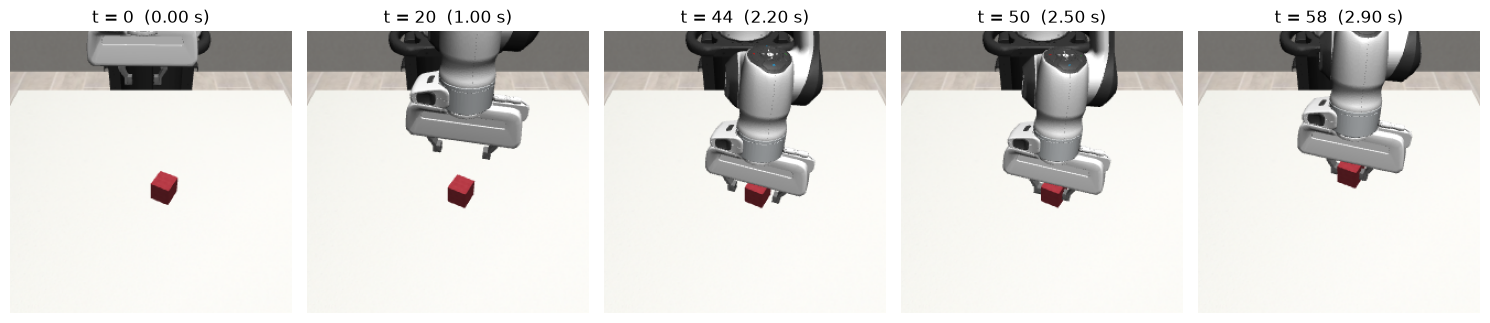

In [3]:
key_steps = [0, 20, 44, 50, 58]
fig, axes = plt.subplots(1, len(key_steps), figsize=(15, 3.4))
for ax, t in zip(axes, key_steps):
    env.reset_to({"states": states[t]})
    ax.imshow(env.render(mode="rgb_array", height=256, width=256, camera_name="agentview"))
    ax.set_title(f"t = {t}  ({t * 0.05:.2f} s)")
    ax.axis("off")
plt.tight_layout()
plt.show()

The arm reaches down, closes on the cube, and lifts it. The whole demonstration lasts about 3 seconds.

## 3. `states[t]`: the exact simulator state

`states[t]` is the information MuJoCo needs to continue the physics. It has 32 numbers:

| Part | Size | Meaning |
| --- | --- | --- |
| time | 1 | Simulator clock, in seconds |
| `qpos` | 16 | Positions: 7 arm joint angles, 2 finger positions, 3 for cube position, 4 for cube rotation |
| `qvel` | 15 | Velocities of those same parts |

The cube has 4 position-like numbers for rotation but only 3 velocity numbers for rotation. That is why `qpos` has 16 and `qvel` has 15.

`states` does **not** directly contain the end-effector pose. The simulator calculates that from the joint angles.

In [4]:
s = states[20]
print("time        ", np.round(s[0], 3))
print("arm joints  ", np.round(s[1:8], 3))
print("fingers     ", np.round(s[8:10], 3))
print("cube pos    ", np.round(s[10:13], 3))
print("cube quat   ", np.round(s[13:17], 3))
print("all velocity", np.round(s[17:], 3).shape)
print("time between stored states:", np.round(np.diff(states[:, 0])[:3], 3), "seconds")

time         1.0
arm joints   [ 0.041  0.643  0.003 -2.065 -0.072  2.726  1.085]
fingers      [ 0.039 -0.039]
cube pos     [0.026 0.027 0.821]
cube quat    [0.247 0.    0.    0.969]
all velocity (15,)
time between stored states: [0.05 0.05 0.05] seconds


## 4. `obs[t]` and `next_obs[t]`

An **observation** is a set of readable measurements, such as "where is the gripper?". Each key has one row per time step.

The recording order is:

```
obs[t]  --->  actions[t]  --->  next_obs[t]
what the      what the          what was true after
robot saw     operator sent     that action finished
```

The next step starts where this step ended. So `next_obs[t]` and `obs[t+1]` describe **the same moment**. The two arrays differ in one way:

- `obs` covers the moments 0 to N-1.
- `next_obs` covers the moments 1 to N.

Only `next_obs[N-1]` shows the moment after the final action. Dataset loaders keep both so each row is a full (before, action, after) sample.

Largest difference between next_obs[t] and obs[t+1]: 0.0


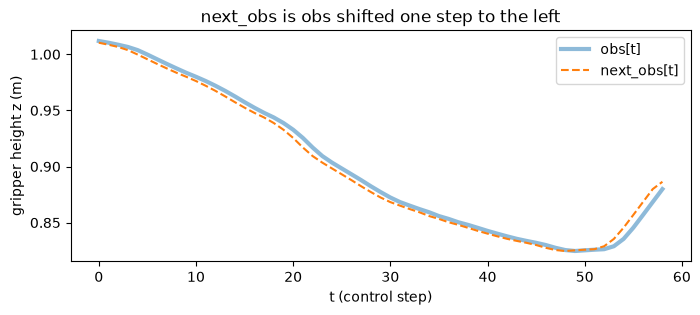

In [5]:
key = "robot0_eef_pos"
print("Largest difference between next_obs[t] and obs[t+1]:", np.abs(next_obs[key][:-1] - obs[key][1:]).max())

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(obs[key][:, 2], label="obs[t]", lw=3, alpha=0.5)
ax.plot(next_obs[key][:, 2], "--", label="next_obs[t]")
ax.set(xlabel="t (control step)", ylabel="gripper height z (m)", title="next_obs is obs shifted one step to the left")
ax.legend()
plt.show()

## 5. `actions[t]`: the commands

`actions[t]` has 7 numbers. Each one lies between -1 and 1. They come from the human operator's input device.

| Index | Meaning | Value of 1.0 means |
| --- | --- | --- |
| 0, 1, 2 | Move along world x, y, z | Aim 0.05 m away from the current position |
| 3, 4, 5 | Rotate about world x, y, z | Aim 0.5 rad away from the current orientation |
| 6 | Gripper | +1 closes, -1 opens |

**The key idea:** an action is a *target*, not a movement. The arm chases the target for 0.05 s and usually does not reach it. Each new action sets a fresh target from wherever the gripper is at that moment. This is what `goal_update_mode = achieved` means.

The plot below shows the difference between the commanded distance and the distance the gripper really moved.

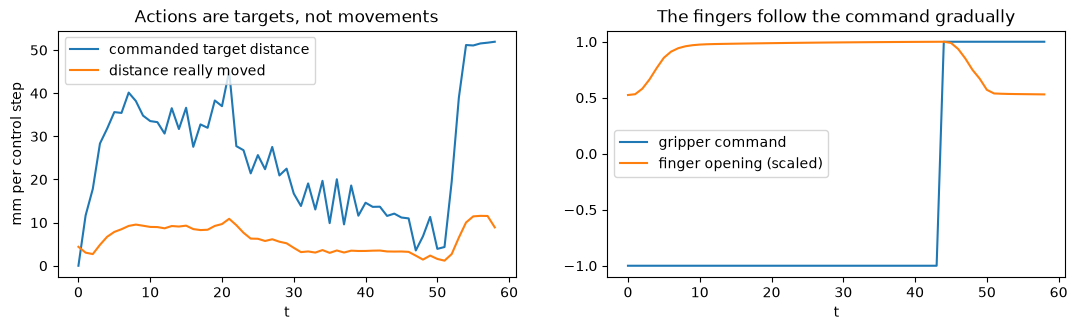

Median commanded 22.5 mm, median moved 5.7 mm
First closing command at t = 44


In [6]:
commanded = np.linalg.norm(actions[:, :3] * 0.05, axis=1)
moved = np.linalg.norm(next_obs["robot0_eef_pos"] - obs["robot0_eef_pos"], axis=1)
gap = states[:, 8] - states[:, 9]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
axes[0].plot(commanded * 1000, label="commanded target distance")
axes[0].plot(moved * 1000, label="distance really moved")
axes[0].set(xlabel="t", ylabel="mm per control step", title="Actions are targets, not movements")
axes[0].legend()
axes[1].plot(actions[:, 6], label="gripper command")
axes[1].plot(gap / gap.max(), label="finger opening (scaled)")
axes[1].set(xlabel="t", title="The fingers follow the command gradually")
axes[1].legend()
plt.show()
print(f"Median commanded {np.median(commanded) * 1000:.1f} mm, median moved {np.median(moved) * 1000:.1f} mm")
print("First closing command at t =", int(np.argmax(actions[:, 6] > 0)))

Step 2 of the project needs this idea. An "absolute action" is the target pose written directly, instead of as a distance from the current pose.

## 6. `reset_to()`: jump to a stored moment

`env.reset_to({"states": states[t]})` works like opening a saved game:

1. It copies time, `qpos` and `qvel` into the simulator.
2. It calls `sim.forward()` so that all calculated values match the new positions.
3. It returns a fresh observation.

No time passes and no physics runs. If you also pass `"model": model_file`, it first rebuilds the whole scene from the stored description.

**What it does not restore:** anything outside the 32 numbers. The gripper keeps a private running value, `current_action`, that moves by 0.2 per control step toward open or closed. `reset_to` leaves it unchanged.

In [7]:
reset_obs = env.reset_to({"states": states[30]})
print("Stored and restored gripper position differ by:", np.abs(reset_obs["robot0_eef_pos"] - obs["robot0_eef_pos"][30]).max())

print("\nGripper private value during a short test:")
print("  now:", gripper.current_action)
for t in range(46, 50):
    env.reset_to({"states": states[t]})
    env.step(actions[t])
print("  after 4 closing commands:", gripper.current_action)
env.reset_to({"states": states[0]})
print("  after jumping back to t = 0:", gripper.current_action, " <- not restored")
rebuild_scene()
print("  after rebuilding the scene:", gripper.current_action)

Stored and restored gripper position differ by: 2.220446049250313e-16

Gripper private value during a short test:
  now: [0.]
  after 4 closing commands: [-0.8  0.8]
  after jumping back to t = 0: [-0.8  0.8]  <- not restored


  after rebuilding the scene: [0.]


This is why the replay check in `inspect_lift_demo.py` could match the arm almost exactly, but not always the fingers.

## 7. `env.step()`, `get_observation()` and `sim.forward()`

These three functions do different jobs.

| Function | Does time pass? | What it does |
| --- | --- | --- |
| `env.step(action)` | Yes, 0.05 s | Runs the controller and 25 physics steps, then returns an observation |
| `sim.forward()` | No | Recalculates values from the current joint angles, such as where the gripper is in space |
| `env.get_observation()` | No | Reads the sensors again, using whatever values the simulator currently holds |

**Why a read can be slightly old.** The simulator keeps two kinds of numbers:

- **Primary values:** joint angles and velocities.
- **Calculated values:** for example, the gripper position in space, worked out from the joint angles.

A physics step calculates the second kind first, and then moves the joints. So at the end of a step, the joints have moved but the calculated gripper position has not caught up. `sim.forward()` fixes this.

Think of a car's dashboard that updates just before the car moves on. `sim.forward()` refreshes the dashboard without moving the car.

The next cell plays the recorded actions in order and compares three reads.

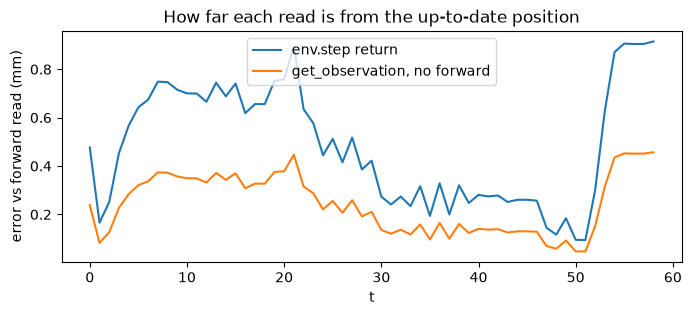

env.step return:  median 0.45 mm, max 0.91 mm
get_observation:  median 0.23 mm, max 0.46 mm


In [8]:
def true_eef_pos():
    '''Return the end-effector position after recalculating the simulator values.

    Returns:
        np.ndarray: Position in the world frame, shape (3,).
    '''
    sim.forward()
    return sim.data.site_xpos[site_id].copy()


# First run: only look at what env.step returned.
rebuild_scene()
step_return_error = []
for t in range(N):
    returned = env.step(actions[t])[0]["robot0_eef_pos"]
    step_return_error.append(np.linalg.norm(returned - true_eef_pos()))

# Second run: only look at get_observation, before calling forward.
rebuild_scene()
get_obs_error = []
for t in range(N):
    env.step(actions[t])
    read = env.get_observation()["robot0_eef_pos"].copy()
    get_obs_error.append(np.linalg.norm(read - true_eef_pos()))

step_return_error, get_obs_error = np.array(step_return_error) * 1000, np.array(get_obs_error) * 1000
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(step_return_error, label="env.step return")
ax.plot(get_obs_error, label="get_observation, no forward")
ax.set(xlabel="t", ylabel="error vs forward read (mm)", title="How far each read is from the up-to-date position")
ax.legend()
plt.show()
print(f"env.step return:  median {np.median(step_return_error):.2f} mm, max {step_return_error.max():.2f} mm")
print(f"get_observation:  median {np.median(get_obs_error):.2f} mm, max {get_obs_error.max():.2f} mm")

The stored dataset matches the `sim.forward()` read, because the replay check found errors near 1e-16 m when no contact was involved. A policy running in the simulator would normally receive the `env.step` return. We should remember this small difference when we reach execution.

## 8. Frames and quaternions

A **frame** is a set of three perpendicular axes attached to something, like a small x-y-z marker. A pose has two parts: where the frame's origin is, and how its axes point.

A **quaternion** is 4 numbers that describe a rotation. Here, each quaternion answers: "how is this frame rotated relative to the world frame?"

| Frame | Attached to | Where you meet it |
| --- | --- | --- |
| **World** | The room. It never moves. | All stored positions and quaternions use it. Actions also use its axes. |
| **Robot base** | The bottom of the arm | Same axes as the world, but a different origin |
| **Grip site** | A marked point between the fingers | `robot0_eef_pos`, `robot0_eef_quat_site`, and the controller |
| **Hand body** | The arm's last part, called `robot0_right_hand` | `robot0_eef_quat` |
| **Cube** | The cube | `obs["object"]`, and `qpos` inside `states` |

**Quaternions you can read:**

| Source | Frame | Number order |
| --- | --- | --- |
| `robot0_eef_quat` | Hand body | x, y, z, w |
| `robot0_eef_quat_site` | Grip site | x, y, z, w |
| `object[3:7]`, named `cube_quat` | Cube | x, y, z, w |
| `states[t][13:17]` | Cube | **w, x, y, z** |

Note the mismatch: the position `robot0_eef_pos` belongs to the grip site, but `robot0_eef_quat` belongs to the hand body. They do not describe one single frame.

In [9]:
env.reset_to({"states": states[0]})

print("Same cube rotation in two number orders:")
print("  object[3:7]    (x, y, z, w):", np.round(obs["object"][0, 3:7], 3))
print("  states[13:17]  (w, x, y, z):", np.round(states[0, 13:17], 3))

body = Rotation.from_quat(obs["robot0_eef_quat"])
site = Rotation.from_quat(obs["robot0_eef_quat_site"])
offset = body.inv() * site
print("\nRotation from hand body to grip site, in degrees about (x, y, z):", np.round(np.degrees(offset[0].as_rotvec()), 2))
print("Change of that rotation over the episode, in degrees:", np.degrees((offset[0].inv() * offset).magnitude()).max().round(6))

controller.update(force=True)
ref = Rotation.from_matrix(controller.ref_ori_mat)
print("\nController frame versus grip site, degrees:", np.degrees((ref.inv() * site[0]).magnitude()).round(5))
print("Controller frame versus hand body, degrees:", np.degrees((ref.inv() * body[0]).magnitude()).round(5))
print("Distance from hand body origin to grip site, m:", np.linalg.norm(sim.data.get_body_xpos("robot0_right_hand") - obs["robot0_eef_pos"][0]).round(4))
print("Robot base position in the world, m:", sim.data.get_body_xpos("robot0_base").round(3))

Same cube rotation in two number orders:
  object[3:7]    (x, y, z, w): [0.    0.    0.969 0.247]
  states[13:17]  (w, x, y, z): [0.247 0.    0.    0.969]

Rotation from hand body to grip site, in degrees about (x, y, z): [ -0.  -0. -90.]
Change of that rotation over the episode, in degrees: 2.1e-05

Controller frame versus grip site, degrees: 0.0
Controller frame versus hand body, degrees: 90.0
Distance from hand body origin to grip site, m: 0.097
Robot base position in the world, m: [-0.56   0.     0.912]


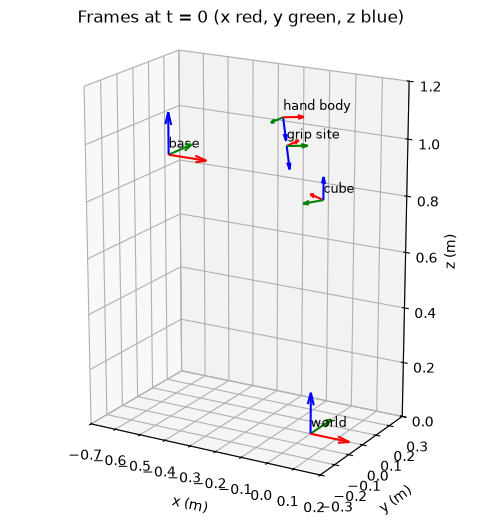

In [10]:
def draw_frame(ax, position, rotation, name, length=0.08):
    '''Draw one frame as red, green and blue arrows for its x, y and z axes.

    Args:
        ax (Axes3D): Plot axes.
        position (np.ndarray): Frame origin, shape (3,).
        rotation (Rotation): Frame orientation in the world frame.
        name (str): Label for the frame.
        length (float): Arrow length in meters.

    Returns:
        None: Nothing.
    '''
    for axis, color in zip(rotation.as_matrix().T, "rgb"):
        ax.quiver(*position, *(axis * length), color=color)
    ax.text(*(position + np.array([0, 0, 0.025])), name, fontsize=9)


fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
identity = Rotation.identity()
draw_frame(ax, np.zeros(3), identity, "world", 0.15)
draw_frame(ax, sim.data.get_body_xpos("robot0_base").copy(), identity, "base", 0.15)
draw_frame(ax, sim.data.get_body_xpos("robot0_right_hand").copy(), body[0], "hand body")
draw_frame(ax, obs["robot0_eef_pos"][0], site[0], "grip site")
draw_frame(ax, obs["object"][0, :3], Rotation.from_quat(obs["object"][0, 3:7]), "cube")
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", xlim=(-0.7, 0.2), ylim=(-0.3, 0.3), zlim=(0, 1.2), title="Frames at t = 0 (x red, y green, z blue)")
ax.set_box_aspect((0.9, 0.6, 1.2))
ax.view_init(18, -60)
plt.show()

**What this means for our method.** The controller works in the grip site frame. Curves on SO(3) × R³ should use one frame for position and orientation, so the grip site is the natural choice. The hand body differs from it by a fixed rotation that never changes, so we can convert between them exactly.

## 9. Common mistakes and one exercise

**Common mistakes**
- Treating an action as the movement that happened. It is only a target.
- Building a pose from `robot0_eef_pos` and `robot0_eef_quat`. These belong to different frames.
- Copying a quaternion between `states` and `obs` without changing the number order.
- Assuming `reset_to` restores everything. It restores only the 32 stored numbers.

**Exercise.** Use `obs["object"]` to find the first step where the cube is more than 1 cm above its starting height. Is this before or after the first closing command? The cube height is `object[:, 2]`.

In [11]:
# One possible answer.
height = obs["object"][:, 2]
raised = int(np.argmax(height > height[0] + 0.01))
closing = int(np.argmax(actions[:, 6] > 0))
print(f"Cube passes 1 cm at t = {raised}, first closing command at t = {closing}")

Cube passes 1 cm at t = 56, first closing command at t = 44


# Part 2: from delta actions to absolute actions

Part 1 explained the recorded dataset. Part 2 explains the new file that `scripts/convert_lift_abs.py` made from it, and why it is built that way.

**What you will be able to do after Part 2:**
- Say what a delta action and an absolute action are, and how to change one into the other.
- Say why adding up the deltas gives the wrong answer.
- Say why a rotation vector can jump when the rotation itself does not.
- Say why the new file needs different controller settings.

**Outline of Part 2**

10. The same command in two forms
11. Why we cannot add up the deltas
12. The goal is not where the gripper is
13. Rotation vectors can jump
14. The file must name the correct controller
15. What changed in the file
16. Common mistakes and one exercise

This part reads both dataset files and writes to neither. It does not test whether absolute actions reproduce the original motion. Step 3 tests that.

## 10. The same command in two forms

Think of giving directions to a walker.

- **Delta action:** "Walk 5 m north from where you are now." The instruction only makes sense if you know where the walker is.
- **Absolute action:** "Walk to the post box." The instruction names the destination itself.

For the arm, the conversion uses the current grip-site pose. The numbers 0.05 and 0.5 are the controller limits from section 5:

$$p^{goal}_t = p_t + 0.05\,a^{pos}_t \qquad\qquad R^{goal}_t = \exp(0.5\,a^{rot}_t)\,R_t$$

The gripper command stays as it is. The absolute action is 7 numbers: goal position (3), goal rotation vector (3), gripper (1).

The next cell works one step by hand, and compares the result with the controller and with the new file. The new file stores the goals in the world frame, for the grip site.

In [12]:
import json

import h5py
from convert_lift_abs import demo_keys, make_env

ABS_PATH = ROOT / "data/robomimic/datasets/lift/ph/low_dim_abs.hdf5"
with h5py.File(ABS_PATH, "r") as f:
    abs_actions = f["data/demo_0/actions"][:]
    abs_env_args = json.loads(f["data"].attrs["env_args"])
    delta_env_args = json.loads(f["data"].attrs["env_args_delta"])
    action_convention = json.loads(f["data"].attrs["action_convention"])

goal_pos, goal_rot = abs_actions[:, :3], Rotation.from_rotvec(abs_actions[:, 3:6])
print("Absolute actions shape:", abs_actions.shape)

Absolute actions shape: (59, 7)


In [13]:
t = 20
rebuild_scene()
env.reset_to({"states": states[t]})
controller.update(force=True)
controller.set_goal(actions[t, :6])

by_hand = obs["robot0_eef_pos"][t] + 0.05 * actions[t, :3]
print("Current position      ", np.round(obs["robot0_eef_pos"][t], 4))
print("Delta action (pos)    ", np.round(actions[t, :3], 4))
print("Goal by hand          ", np.round(by_hand, 4))
print("Goal from controller  ", np.round(controller.goal_pos, 4))
print("Goal in the new file  ", np.round(abs_actions[t, :3], 4))

rotation_by_hand = Rotation.from_rotvec(0.5 * actions[t, 3:6]) * Rotation.from_quat(obs["robot0_eef_quat_site"][t])
print("\nRotation: by hand vs new file, degrees:", np.degrees((rotation_by_hand.inv() * goal_rot[t]).magnitude()).round(5))

Current position       [0.023  0.0261 0.9328]
Delta action (pos)     [ 0.388 -0.007 -0.63 ]
Goal by hand           [0.0424 0.0257 0.9013]
Goal from controller   [0.0424 0.0257 0.9013]
Goal in the new file   [0.0424 0.0257 0.9013]

Rotation: by hand vs new file, degrees: 0.0


All three goal positions agree, and so does the rotation. Over all demonstrations, the largest rotation difference is 7e-7 rad. The stored site quaternion uses float32 numbers, which is the likely cause.

The script reads the goal from the controller. It does not call `robot.control` or run any physics, so nothing moves. The formula above is only an independent check.

## 11. Why we cannot add up the deltas

A natural idea is to start at the first position and add up all the deltas. That would be correct only if the arm reached every target.

Section 5 showed that it does not. Each action starts again from where the gripper **really is**, not from the previous target. So adding up the deltas counts movement that never happened.

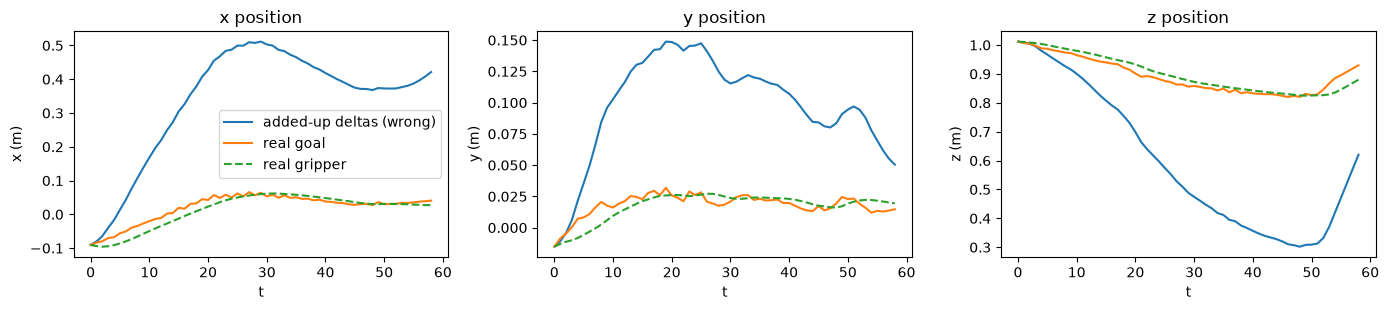

Added-up deltas end 49.2 cm from the real final goal


In [14]:
added_up = obs["robot0_eef_pos"][0] + np.cumsum(actions[:, :3] * 0.05, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharex=True)
for i, (ax, name) in enumerate(zip(axes, "xyz")):
    ax.plot(added_up[:, i], label="added-up deltas (wrong)")
    ax.plot(goal_pos[:, i], label="real goal")
    ax.plot(obs["robot0_eef_pos"][:, i], "--", label="real gripper")
    ax.set(xlabel="t", ylabel=f"{name} (m)", title=f"{name} position")
axes[0].legend()
plt.tight_layout()
plt.show()
print(f"Added-up deltas end {np.linalg.norm(added_up[-1] - goal_pos[-1]) * 100:.1f} cm from the real final goal")

## 12. The goal is not where the gripper is

The new file stores **targets**, not the path the gripper followed. The target stays ahead of the gripper while the arm moves, like a carrot on a stick. When the arm moves slowly, the two come close together.

This matters for later steps: a curve fitted to goals describes what the controller was asked to do, not what the gripper did.

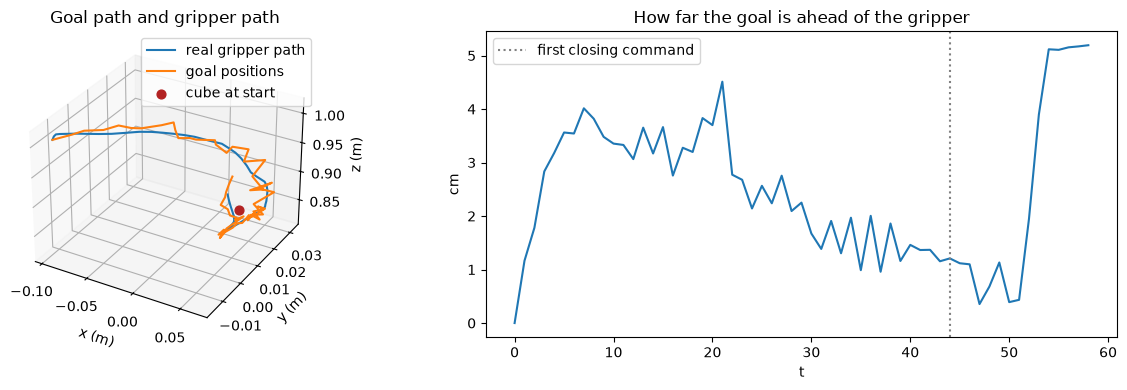

Goal ahead of gripper: median 2.3 cm, max 5.2 cm


In [15]:
gripper_path = obs["robot0_eef_pos"]
lead = np.linalg.norm(goal_pos - gripper_path, axis=1) * 100

fig = plt.figure(figsize=(13, 4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(*gripper_path.T, label="real gripper path")
ax.plot(*goal_pos.T, label="goal positions")
ax.scatter(*obs["object"][0, :3], color="firebrick", s=40, label="cube at start")
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title="Goal path and gripper path")
ax.legend()
ax = fig.add_subplot(1, 2, 2)
ax.plot(lead)
ax.axvline(44, color="gray", ls=":", label="first closing command")
ax.set(xlabel="t", ylabel="cm", title="How far the goal is ahead of the gripper")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Goal ahead of gripper: median {np.median(lead):.1f} cm, max {lead.max():.1f} cm")

## 13. Rotation vectors can jump

A **rotation vector** stores a rotation in 3 numbers. Its direction is the axis to turn around, and its length is the angle to turn.

The angle only goes up to π (180°), because turning further is the same as turning the other way. So 179° about an axis and 179° about the opposite axis are nearly the same rotation, even though their numbers are far apart.

It is like a clock: 11:59 and 12:01 are 2 minutes apart, but the number on the display jumps a long way.

This matters here because the gripper points **down** and the world's z axis points **up**. The grip site is therefore always close to a 180° rotation from the world frame, right beside the place where the numbers jump.

The next cell finds a demonstration with a jump. It compares the stored numbers with the true rotation change.

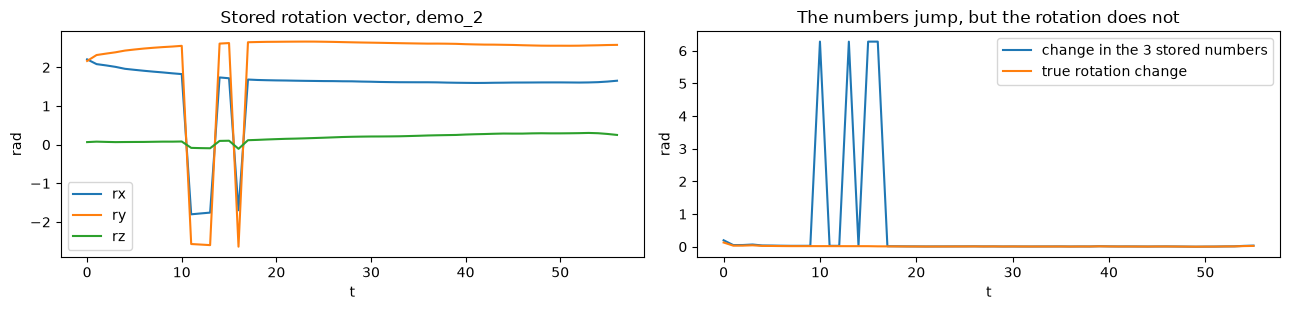

At t = 10 in demo_2:
  stored numbers change by 6.282
  true rotation changes by 0.017 rad


In [16]:
with h5py.File(ABS_PATH, "r") as f:
    for key in demo_keys(f["data"]):
        rotvecs = f[f"data/{key}/actions"][:, 3:6]
        number_change = np.linalg.norm(np.diff(rotvecs, axis=0), axis=1)
        if number_change.max() > 1.0:
            break
rotations = Rotation.from_rotvec(rotvecs)
true_change = (rotations[:-1].inv() * rotations[1:]).magnitude()
jump = int(number_change.argmax())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for i, name in enumerate(["rx", "ry", "rz"]):
    axes[0].plot(rotvecs[:, i], label=name)
axes[0].set(xlabel="t", ylabel="rad", title=f"Stored rotation vector, {key}")
axes[0].legend()
axes[1].plot(number_change, label="change in the 3 stored numbers")
axes[1].plot(true_change, label="true rotation change")
axes[1].set(xlabel="t", ylabel="rad", title="The numbers jump, but the rotation does not")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"At t = {jump} in {key}:")
print(f"  stored numbers change by {number_change[jump]:.3f}")
print(f"  true rotation changes by {true_change[jump]:.3f} rad")

**Why this matters: averaging.** Suppose a method treats the 3 numbers as ordinary coordinates and averages the two rotations on either side of the jump. The next cell compares that with the true halfway rotation.

In [17]:
before, after = rotvecs[jump], rotvecs[jump + 1]
naive_middle = Rotation.from_rotvec((before + after) / 2)
true_middle = Rotation.from_rotvec(before) * Rotation.from_rotvec(0.5 * (Rotation.from_rotvec(before).inv() * Rotation.from_rotvec(after)).as_rotvec())

print("Rotation before:", np.round(before, 3))
print("Rotation after: ", np.round(after, 3))
print(f"Averaging the numbers gives a rotation {np.degrees((naive_middle.inv() * true_middle).magnitude()):.1f} degrees from the true middle")

Rotation before: [1.825 2.556 0.081]
Rotation after:  [-1.802 -2.571 -0.084]
Averaging the numbers gives a rotation 180.0 degrees from the true middle


This is why later steps must not fit curves to these 3 numbers directly. We must turn them into rotations first, and then use our SO(3) operations. The robot itself is not affected, because both sides of a jump are valid rotations.

## 14. The file must name the correct controller

The same 7 numbers mean different things to different controllers. So the new file stores its own controller settings:

| Attribute in the new file | Creates |
| --- | --- |
| `env_args` | Absolute controller |
| `env_args_delta` | The original delta controller |
| `action_convention` | A plain record of frames and units |

The next cells build the absolute controller and give it the stored goal. Then they show what would go wrong if a delta controller received those same numbers. Both tests only set a goal. No physics runs.

In [18]:
arm_settings = abs_env_args["env_kwargs"]["controller_configs"]["body_parts"]["right"]
delta_settings = delta_env_args["env_kwargs"]["controller_configs"]["body_parts"]["right"]
print("env_args:        input_type =", arm_settings.get("input_type"), "| control_delta =", arm_settings.get("control_delta"))
print("env_args_delta:  input_type =", delta_settings.get("input_type"), "| control_delta =", delta_settings.get("control_delta"))
print("\naction_convention:")
for name, value in action_convention.items():
    print(f"  {name}: {value}")

env_args:        input_type = absolute | control_delta = None
env_args_delta:  input_type = None | control_delta = True

action_convention:
  type: absolute
  position: world-frame grip-site target position (m), actions[:, 0:3]
  orientation: rotation vector of the world-frame grip-site target orientation (rad), actions[:, 3:6]
  gripper: original gripper command, actions[:, 6]
  goal_source: OSC_POSE controller goal_pos and goal_ori after set_goal on the stored delta action
  source_sha256: 2067777cb8b532e9263dd09fd6448c41cc31224bb27be4a3b734010ae13eb540


In [19]:
abs_env = make_env(abs_env_args, obs)
abs_controller = arm_controller(abs_env)

t = 20
abs_env.reset_to({"states": states[t]})
abs_controller.update(force=True)
abs_controller.set_goal(abs_actions[t, :6])
right_error = np.linalg.norm(abs_controller.goal_pos - goal_pos[t])

# The mistake: give the same absolute numbers to the delta controller.
rebuild_scene()
env.reset_to({"states": states[t]})
controller.update(force=True)
controller.set_goal(abs_actions[t, :6])
wrong_error = np.linalg.norm(controller.goal_pos - goal_pos[t])

print(f"Absolute controller goal is {right_error * 100:.4f} cm from the intended goal")
print(f"Delta controller goal is    {wrong_error * 100:.1f} cm from the intended goal")


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qpos', 'object', 'robot0_eef_pos', 'robot0_joint_vel', 'robot0_joint_pos_cos', 'robot0_eef_quat', 'robot0_joint_pos', 'robot0_eef_quat_site', 'robot0_joint_pos_sin', 'robot0_gripper_qvel']
using obs modality: rgb with keys: []


Created environment with name Lift
Action size is 7


Absolute controller goal is 0.0000 cm from the intended goal
Delta controller goal is    7.9 cm from the intended goal


With the wrong controller, there is no error message. The robot simply receives a wrong target. This is why the new file's `env_args` creates the absolute controller by itself.

## 15. What changed in the file

Only the first six action columns and the metadata changed. The next cell checks `demo_0`. `scripts/validate_lift_abs.py` runs the same comparison on all 200 demonstrations.

In [20]:
source_path = ROOT / "data/robomimic/datasets/lift/ph/low_dim_v15.hdf5"
with h5py.File(source_path, "r") as a, h5py.File(ABS_PATH, "r") as b:
    d0, d1 = a["data/demo_0"], b["data/demo_0"]
    print("Pose actions changed:      ", not np.array_equal(d0["actions"][:, :6], d1["actions"][:, :6]))
    print("Gripper commands identical:", np.array_equal(d0["actions"][:, 6], d1["actions"][:, 6]))
    print("States identical:          ", np.array_equal(d0["states"][:], d1["states"][:]))
    print("All obs identical:         ", all(np.array_equal(d0["obs"][k][:], d1["obs"][k][:]) for k in d0["obs"]))
    print("All next_obs identical:    ", all(np.array_equal(d0["next_obs"][k][:], d1["next_obs"][k][:]) for k in d0["next_obs"]))

print("\nOne action, t = 20")
print("  delta:   ", np.round(actions[20], 3))
print("  absolute:", np.round(abs_actions[20], 3))

Pose actions changed:       True
Gripper commands identical: True
States identical:           True
All obs identical:          True
All next_obs identical:     True

One action, t = 20
  delta:    [ 0.388 -0.007 -0.63  -0.038 -0.01  -0.12  -1.   ]
  absolute: [ 0.042  0.026  0.901  2.44   1.896 -0.016 -1.   ]


## 16. Common mistakes and one exercise

**Common mistakes**
- Adding up deltas to find the goal. Each delta starts from the real gripper pose.
- Treating goals as the path the gripper followed. Goals stay ahead of it.
- Averaging or fitting rotation vectors as if they were ordinary coordinates.
- Giving absolute actions to a delta controller. No error appears.
- Clipping absolute actions to the range -1 to 1. These values are meters and radians, so clipping would destroy them.

**Exercise.** Find the step in `demo_0` where the goal is farthest ahead of the gripper. Then look at `actions[t, :3]` at that step. Is the largest number close to 1? Use `lead` from section 12.

In [21]:
# One possible answer.
farthest = int(lead.argmax())
print(f"Farthest at t = {farthest}, {lead[farthest]:.2f} cm ahead")
print("Delta position command there:", np.round(actions[farthest, :3], 3))

Farthest at t = 58, 5.19 cm ahead
Delta position command there: [ 0.264 -0.095  1.   ]
